# TP N° 1: Análisis Técnico y Clustering de Regímenes de Mercado

# Alumno: LUIS APUT

**Instalación de Dependencias**

**Importaciones y Definición de Activos a utilizar**

Punto A: Selección de Activos Financieros

In [15]:
import yfinance as yf
import ta
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Definimos los 3 tickers a analizar
# NVDA: Ejemplo Sobrecomprada / Tendencia Alcista
# NKE: Ejemplo Sobrevendida / Tendencia Bajista
# BRK-B: Ejemplo Estable / Consolidación

tickers = {
    'Sobrecomprada': 'NVDA',
    'Sobrevendida': 'NKE',
    'Estable': 'BRK-B'
}

# Función completa con los nombres de columna exactos para el Panel MACD
def calcular_indicadores(df):
    df = df.copy()

    # RSI
    df['RSI'] = ta.momentum.rsi(df['Close'], window=14)

    # SMA (Media Móvil Simple)
    df['SMA_20'] = ta.trend.sma_indicator(df['Close'], window=20)
    df['SMA_50'] = ta.trend.sma_indicator(df['Close'], window=50)

    # MACD (Línea, Señal e Histograma con mayúsculas exactas)
    df['MACD'] = ta.trend.macd(df['Close'])
    df['MACD_Signal'] = ta.trend.macd_signal(df['Close'])
    df['MACD_Hist'] = ta.trend.macd_diff(df['Close'])

    # Bandas de Bollinger
    df['BB_Upper'] = ta.volatility.bollinger_hband(df['Close'], window=20)
    df['BB_Lower'] = ta.volatility.bollinger_lband(df['Close'], window=20)

    # ADX y Indicadores Direccionales (+DI y -DI)
    df['ADX'] = ta.trend.adx(df['High'], df['Low'], df['Close'], window=14)
    df['PLUS_DI'] = ta.trend.adx_pos(df['High'], df['Low'], df['Close'], window=14)
    df['MINUS_DI'] = ta.trend.adx_neg(df['High'], df['Low'], df['Close'], window=14)

    # Momentum (10 días)
    df['MOM'] = ta.momentum.roc(df['Close'], window=10)

    # Normalización para Clustering
    df['Dist_SMA20'] = (df['Close'] - df['SMA_20']) / df['SMA_20']
    df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['SMA_20']

    # Retornos logarítmicos
    df['Returns'] = np.log(df['Close'] / df['Close'].shift(1))

    return df

# 2. Descargar datos del último año y calcular indicadores
data_dict = {}
for estado, ticker in tickers.items():
    print(f"Descargando datos del último año para {ticker} ({estado})...")
    df = yf.download(ticker, period="1y", interval="1d")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = calcular_indicadores(df)
    data_dict[ticker] = (estado, df)

Descargando datos del último año para NVDA (Sobrecomprada)...


[*********************100%***********************]  1 of 1 completed


Descargando datos del último año para NKE (Sobrevendida)...


[*********************100%***********************]  1 of 1 completed


Descargando datos del último año para BRK-B (Estable)...


[*********************100%***********************]  1 of 1 completed


**Visualización de Indicadores Técnicos**

Punto B: Visualización Gráfica del Análisis Técnico

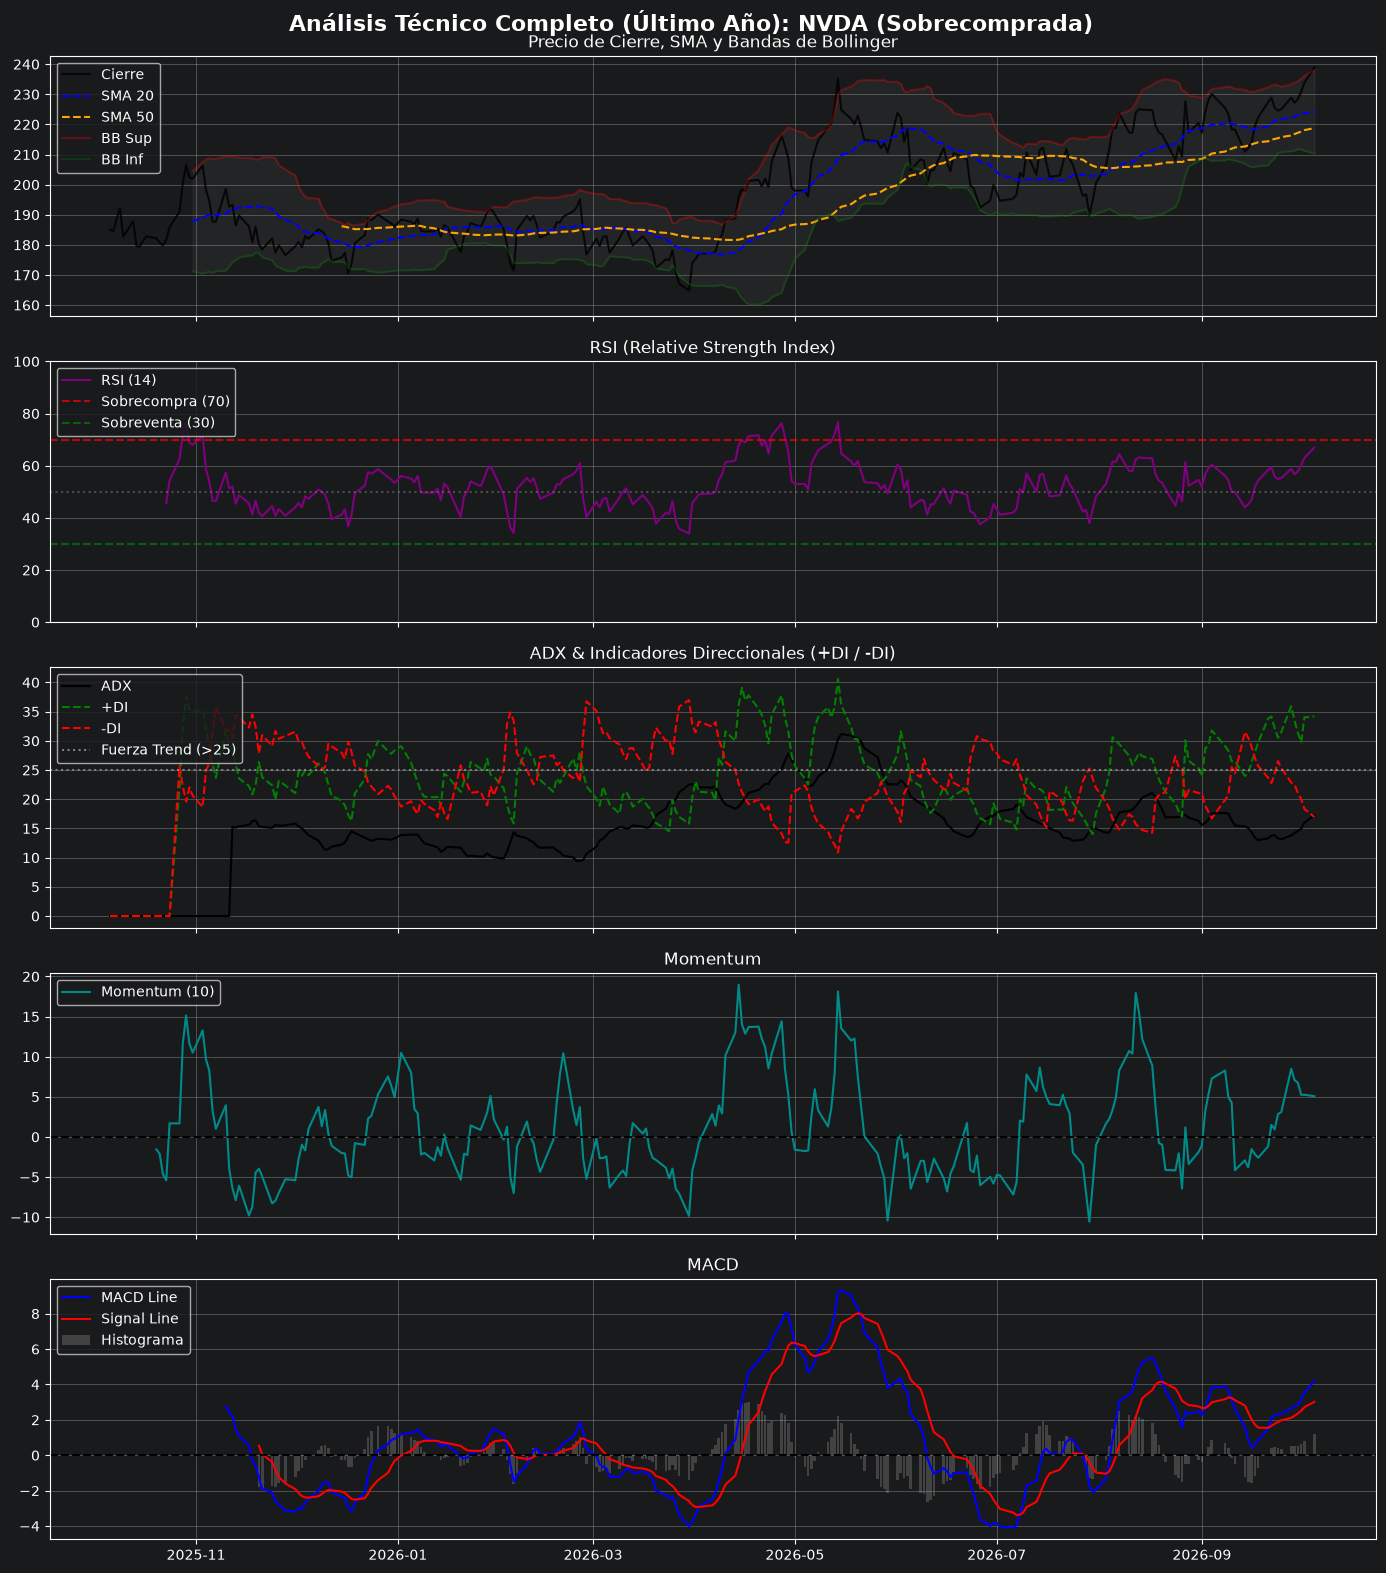

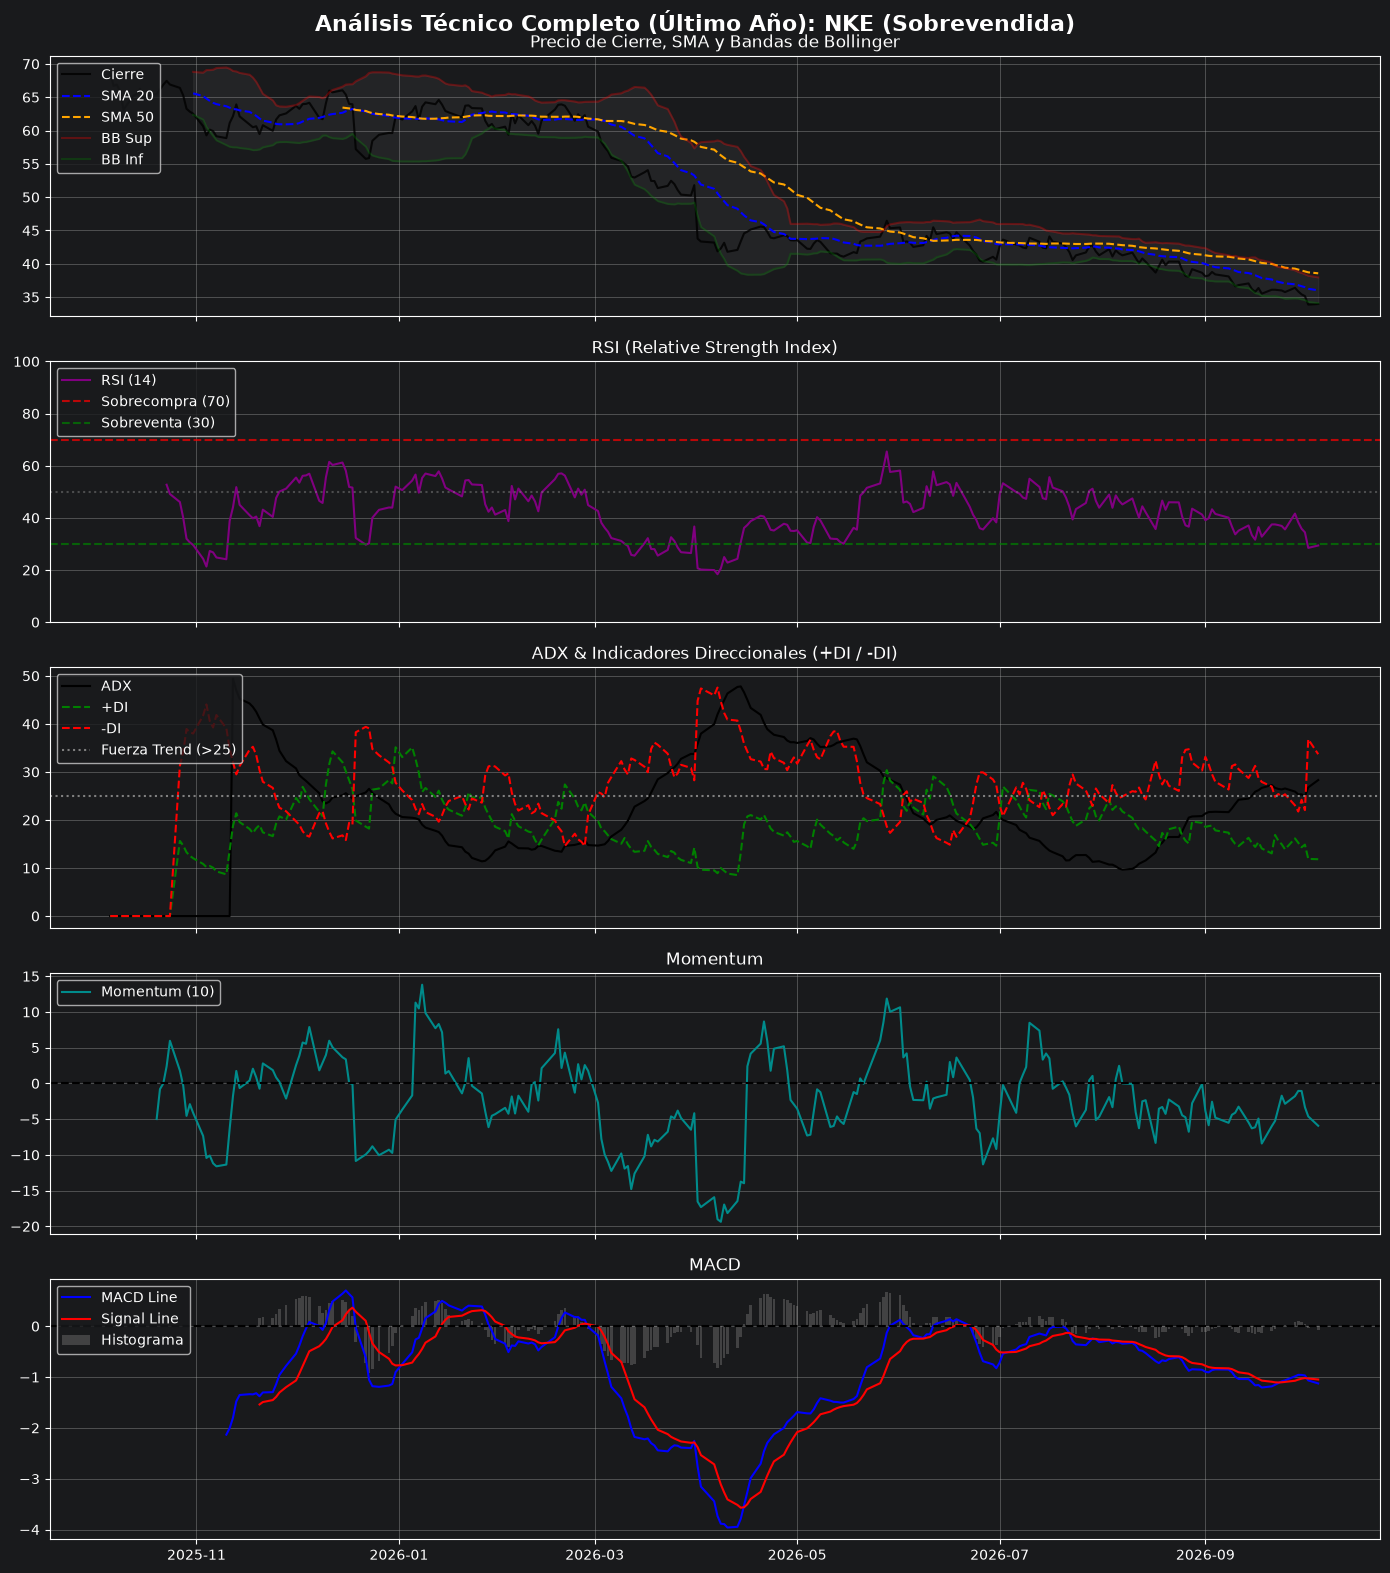

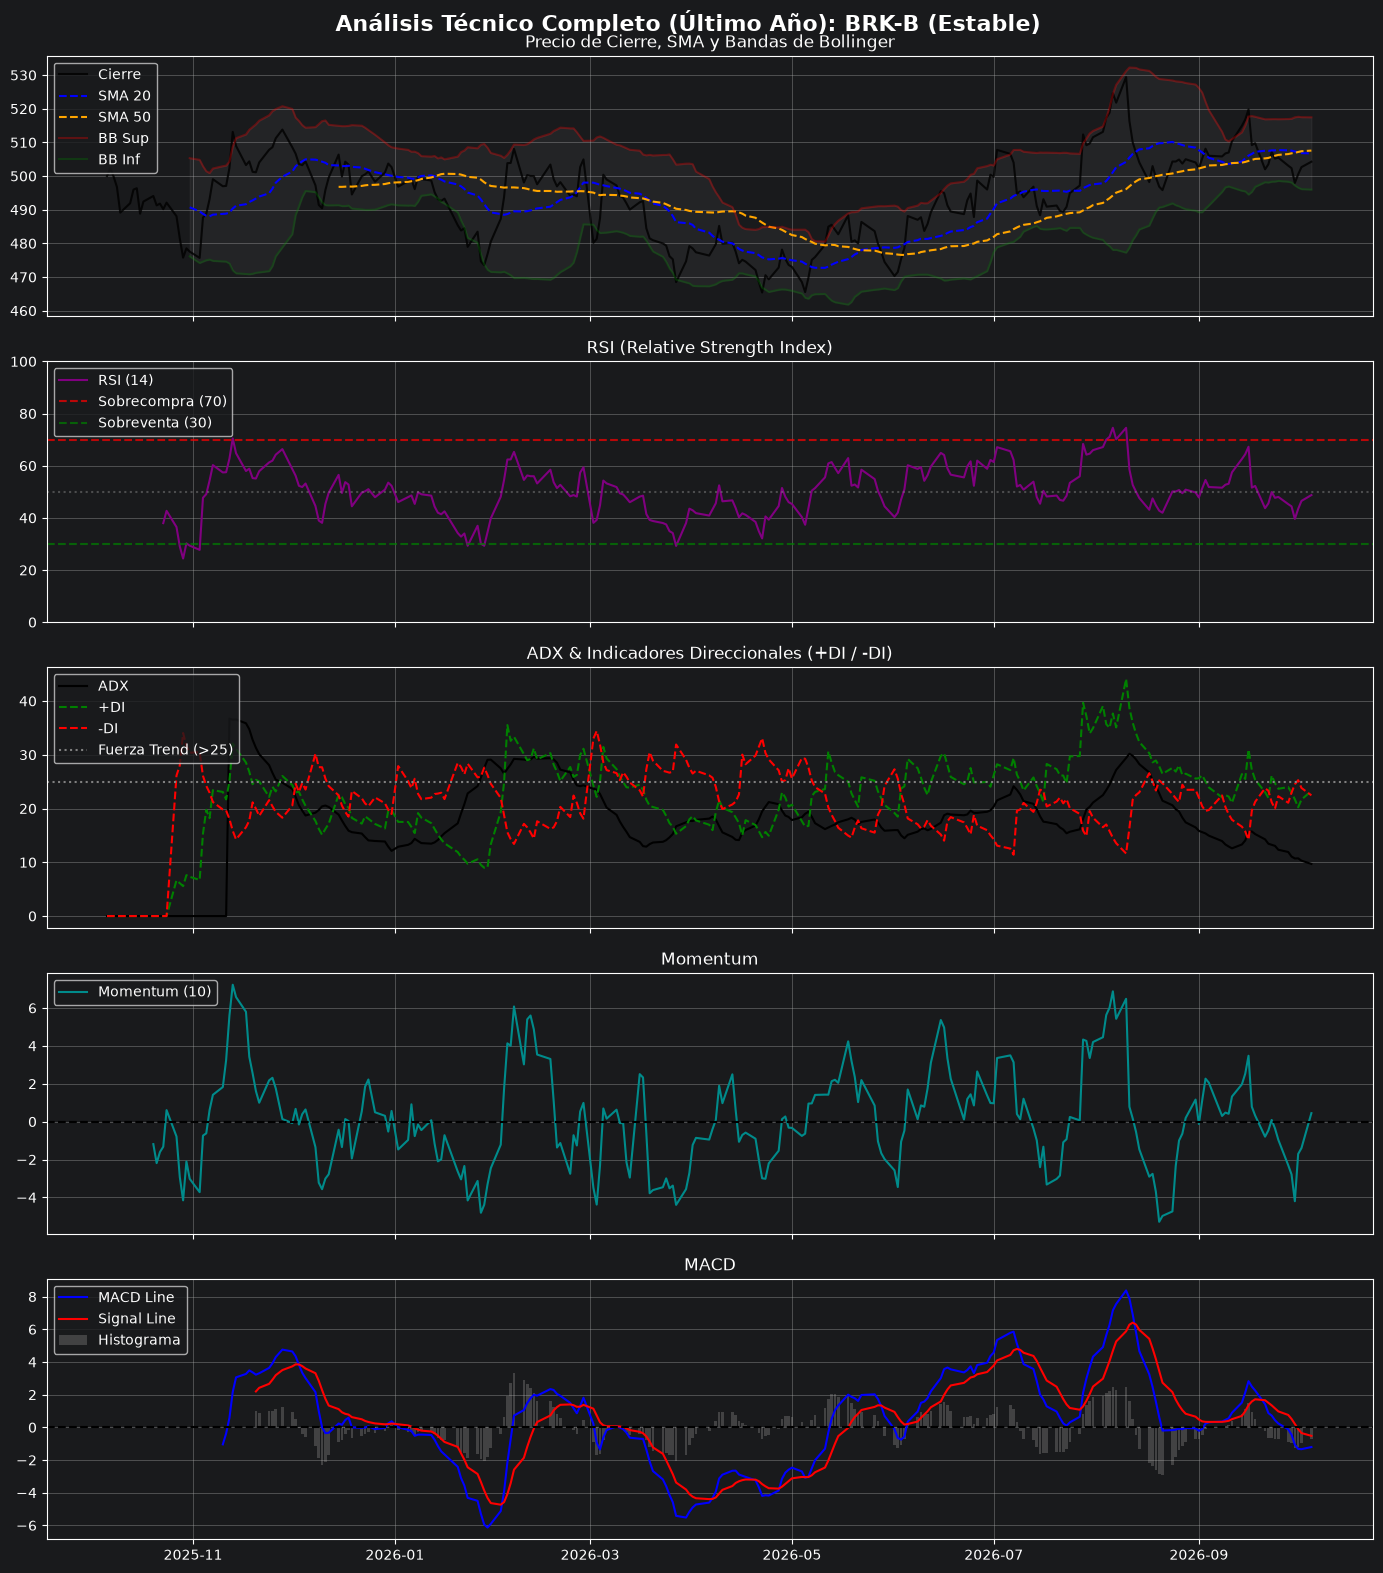

In [16]:
# 3. Función para graficar la batería completa de indicadores por Ticker
def graficar_analisis_completo(ticker, estado, df):
    fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)
    fig.suptitle(f'Análisis Técnico Completo (Último Año): {ticker} ({estado})', fontsize=16, fontweight='bold')

    # Panel 1: Precios, SMA y Bollinger Bands
    axes[0].plot(df.index, df['Close'], label='Cierre', color='black', alpha=0.8)
    axes[0].plot(df.index, df['SMA_20'], label='SMA 20', color='blue', linestyle='--')
    axes[0].plot(df.index, df['SMA_50'], label='SMA 50', color='orange', linestyle='--')
    axes[0].plot(df.index, df['BB_Upper'], label='BB Sup', color='red', alpha=0.3)
    axes[0].plot(df.index, df['BB_Lower'], label='BB Inf', color='green', alpha=0.3)
    axes[0].fill_between(df.index, df['BB_Lower'], df['BB_Upper'], color='gray', alpha=0.1)
    axes[0].set_title('Precio de Cierre, SMA y Bandas de Bollinger')
    axes[0].legend(loc='upper left')
    axes[0].grid(True)

    # Panel 2: RSI
    axes[1].plot(df.index, df['RSI'], label='RSI (14)', color='purple')
    axes[1].axhline(70, color='red', linestyle='--', alpha=0.7, label='Sobrecompra (70)')
    axes[1].axhline(30, color='green', linestyle='--', alpha=0.7, label='Sobreventa (30)')
    axes[1].axhline(50, color='gray', linestyle=':', alpha=0.5)
    axes[1].set_title('RSI (Relative Strength Index)')
    axes[1].set_ylim(0, 100)
    axes[1].legend(loc='upper left')
    axes[1].grid(True)

    # Panel 3: ADX y DIs
    axes[2].plot(df.index, df['ADX'], label='ADX', color='black', linewidth=1.5)
    axes[2].plot(df.index, df['PLUS_DI'], label='+DI', color='green', linestyle='--')
    axes[2].plot(df.index, df['MINUS_DI'], label='-DI', color='red', linestyle='--')
    axes[2].axhline(25, color='gray', linestyle=':', label='Fuerza Trend (>25)')
    axes[2].set_title('ADX & Indicadores Direccionales (+DI / -DI)')
    axes[2].legend(loc='upper left')
    axes[2].grid(True)

    # Panel 4: Momentum
    axes[3].plot(df.index, df['MOM'], label='Momentum (10)', color='darkcyan')
    axes[3].axhline(0, color='black', linestyle='--')
    axes[3].set_title('Momentum')
    axes[3].legend(loc='upper left')
    axes[3].grid(True)

    # Panel 5: MACD
    axes[4].plot(df.index, df['MACD'], label='MACD Line', color='blue')
    axes[4].plot(df.index, df['MACD_Signal'], label='Signal Line', color='red')
    axes[4].bar(df.index, df['MACD_Hist'], label='Histograma', color='gray', alpha=0.4)
    axes[4].axhline(0, color='black', linestyle='--')
    axes[4].set_title('MACD')
    axes[4].legend(loc='upper left')
    axes[4].grid(True)

    plt.tight_layout()
    plt.show()

# Graficar para los 3 tickers
for ticker, (estado, df) in data_dict.items():
    graficar_analisis_completo(ticker, estado, df)

**Clustering de Regímenes de Mercado**

Punto C: Estudio de Regímenes de Mercado mediante Aprendizaje No Supervisado (K-Means)


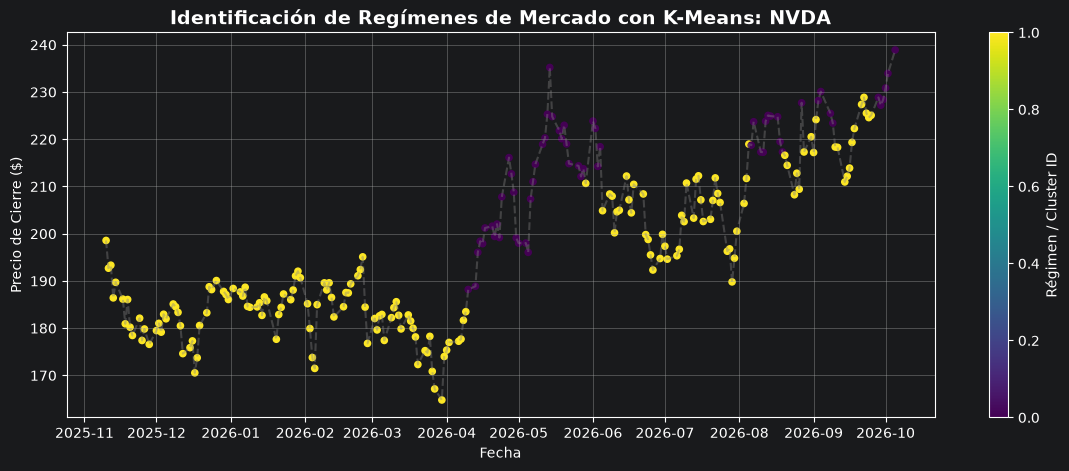

--- Promedio de Indicadores y Precio por Régimen/Clúster para NVDA ---
Price         Close        RSI        ADX       MOM      MACD
Regimen                                                      
0        215.599624  61.820161  22.074836  6.702599  5.048048
1        192.643261  48.645991  14.601960 -1.246080 -0.419586




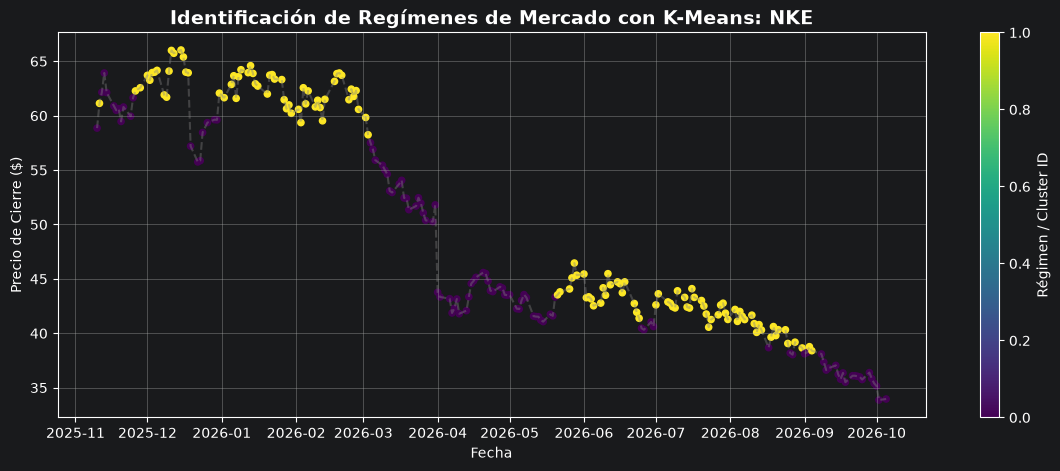

--- Promedio de Indicadores y Precio por Régimen/Clúster para NKE ---
Price        Close        RSI        ADX       MOM      MACD
Regimen                                                     
0        46.332755  34.350341  30.977910 -5.684175 -1.695290
1        51.970988  49.380605  17.905031  0.578091 -0.197082




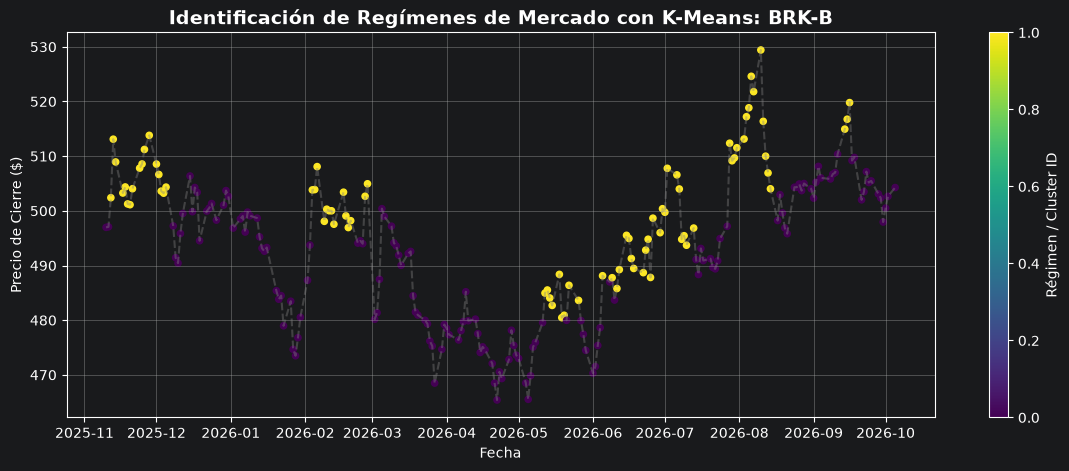

--- Promedio de Indicadores y Precio por Régimen/Clúster para BRK-B ---
Price         Close        RSI        ADX       MOM      MACD
Regimen                                                      
0        489.873493  45.871123  17.047567 -1.089951 -1.073017
1        501.464249  59.750281  23.463829  2.558393  3.217732




In [17]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

def analizar_regimenes_clustering(ticker, df, n_clusters=2):
    # 1. Seleccionar características (features) sin valores nulos
    df_clean = df.dropna(subset=['RSI', 'ADX', 'MOM', 'MACD', 'PLUS_DI', 'MINUS_DI', 'Close']).copy()

    features = ['RSI', 'ADX', 'MOM', 'MACD']
    X = df_clean[features]

    # 2. Escalado de datos
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # 3. Aplicar K-Means Clustering
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df_clean['Regimen'] = kmeans.fit_predict(X_scaled)

    # 4. Graficar los regímenes detectados sobre la curva de precios
    plt.figure(figsize=(14, 5))
    scatter = plt.scatter(df_clean.index, df_clean['Close'], c=df_clean['Regimen'], cmap='viridis', s=20)
    plt.plot(df_clean.index, df_clean['Close'], color='gray', alpha=0.4, linestyle='--')
    plt.colorbar(scatter, label='Régimen / Cluster ID')
    plt.title(f'Identificación de Regímenes de Mercado con K-Means: {ticker}', fontsize=14, fontweight='bold')
    plt.xlabel('Fecha')
    plt.ylabel('Precio de Cierre ($)')
    plt.grid(True)
    plt.show()

    # Resumen medio de características y precio por clúster
    print(f"--- Promedio de Indicadores y Precio por Régimen/Clúster para {ticker} ---")
    summary = df_clean.groupby('Regimen')[['Close'] + features].mean()
    print(summary)
    print("\n" + "="*60 + "\n")

# Ejecutar el clustering para los tickers analizados
for ticker, (estado, df) in data_dict.items():
    analizar_regimenes_clustering(ticker, df, n_clusters=2)

**Conclusiones y Resumen Final**

Los gráficos y las tablas demostraron que el algoritmo K-Means logro clasificar los momentos de baja/alta volatilidad y tendencia. Identificó la aceleración en NVDA, el desplome de NKE y los micro-ciclos laterales en BRK-B.

* NVDA Sobrecomprada / Alcista:
   AT: Mostró picos marcados de sobrecompra en el RSI y niveles de ADX elevados, confirmando un impulso fuertemente comprador.
   Clustering:
   Morado Régimen 0 - Consolidación / Pausa
   Amarillo Régimen 1 - Impulso / Sobrecompra

* NKE Sobrevendida / Bajista:
   AT: Se ve el RSI cercano a 30 y un ADX superior a 30 en los tramos de caída libre, reflejando una fuerte presión vendedora.
   Clustering:
   Morado Régimen 0 - Presión Bajista / Sobreventa
   Amarillo Régimen 1 - Consolidación / Rebote

* BRK-B Estable / Consolidación:
   AT: Movimientos acotados en un rango lateral entre los $465 y $530, con un ADX por debajo de 25 mayormente y un RSI oscilando en torno a los 50 puntos sin llegar a extremos. Al no existir una tendencia macro dominante, K-Means dividió el comportamiento en micro-ciclos dentro del rango.
   Clustering:
   Clúster Morado Régimen 0 - Parte Baja del Rango
   Clúster Amarillo Régimen 1 - Parte Alta del Rango